In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv('garments_worker_productivity.csv')

df.head(5)

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [4]:
print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (1197, 15)
<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   str    
 1   quarter                1197 non-null   str    
 2   department             1197 non-null   str    
 3   day                    1197 non-null   str    
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   fl

In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn

   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.6 MB 9.6 MB/s eta 0:00:01
   --------------- ------------------------ 3.7/9.6 MB 8.9 MB/s eta 0:00:01
   ----------------------- ---------------- 5.8/9.6 MB 9.0 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.6 MB 9.4 MB/s eta 0:00:01
   ---------------------------------------- 9.6/9.6 MB 9.4 MB/s  0:00:01
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ------- -------------------------------- 2.4/12.6 MB 11.5 MB/s eta 0:00:01
   --------------- ------------------------ 4.7/12.6 MB 11.5 MB/s eta 0:00:01
   --------------------- ------------------ 6.8/12.6 MB 11.5 MB/s eta 0:00:01
   ------------------------------ --------- 9.4/12.6 MB 11.6 MB/s eta 0:00:01
   -------------------------------------- - 12.1/12.6 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 11.4 MB/s  0:00:01
   --------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
missing_summary = df.isnull().sum()
print("Missing Values Summary:")
print(missing_summary[missing_summary > 0])

Missing Values Summary:
wip    506
dtype: int64


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
team,1197.0,6.426901,3.463963,1.000000,3.000000,6.000000,9.000000,12.000000
targeted_productivity,1197.0,0.729632,0.097891,0.070000,0.700000,0.750000,0.800000,0.800000
smv,1197.0,15.062172,10.943219,2.900000,3.940000,15.260000,24.260000,54.560000
wip,691.0,1190.465991,1837.455001,7.000000,774.500000,1039.000000,1252.500000,23122.000000
over_time,1197.0,4567.460317,3348.823563,0.000000,1440.000000,3960.000000,6960.000000,25920.000000
incentive,1197.0,38.210526,160.182643,0.000000,0.000000,0.000000,50.000000,3600.000000
idle_time,1197.0,0.730159,12.709757,0.000000,0.000000,0.000000,0.000000,300.000000
idle_men,1197.0,0.369256,3.268987,0.000000,0.000000,0.000000,0.000000,45.000000
no_of_style_change,1197.0,0.150376,0.427848,0.000000,0.000000,0.000000,0.000000,2.000000
no_of_workers,1197.0,34.609858,22.197687,2.000000,9.000000,34.000000,57.000000,89.000000


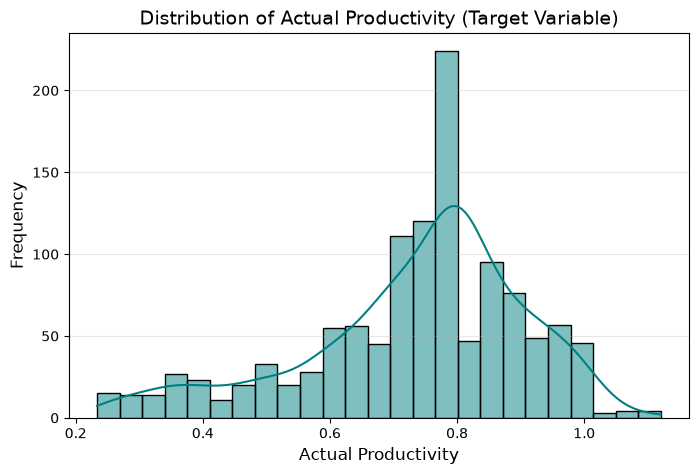

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(8, 5))
sns.histplot(df['actual_productivity'], kde=True, color='teal', bins=25)

plt.title('Distribution of Actual Productivity (Target Variable)', fontsize=14)
plt.xlabel('Actual Productivity', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.show()

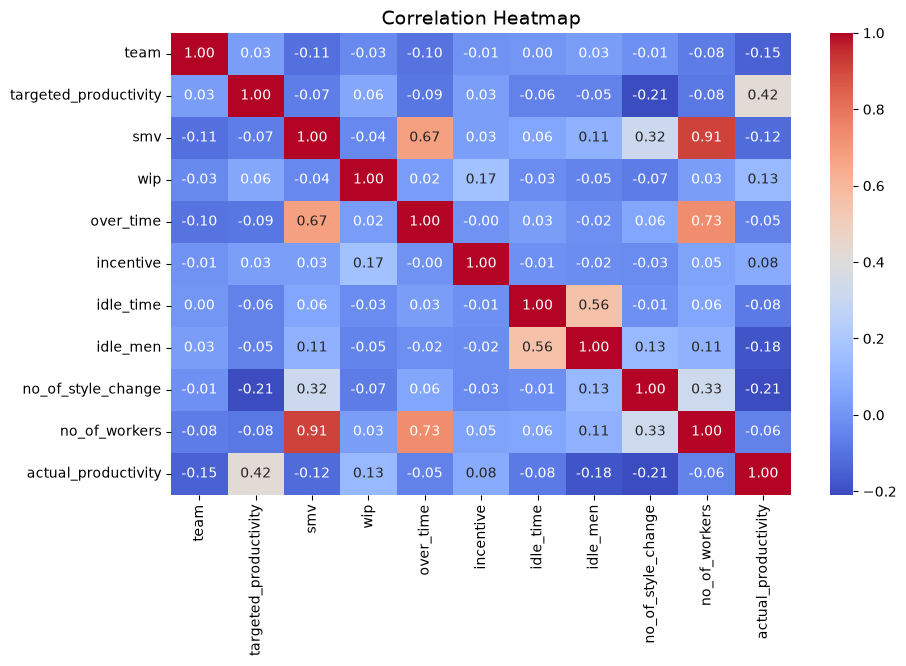

In [10]:
# Plot 2: Correlation Heatmap
plt.figure(figsize=(10, 6))
numeric_df = df.select_dtypes(include=['float64', 'int64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap', fontsize=14)
plt.show()

In [ ]:
caregorical_cols = ['quarter', 'department', 'day']
for col in caregorical_cols:
    print(f"Unique values in '{col}':", df[col].unique())

Unique values in 'quarter': <StringArray>
['Quarter1', 'Quarter2', 'Quarter3', 'Quarter4', 'Quarter5']
Length: 5, dtype: str
Unique values in 'department': <StringArray>
['sweing', 'finishing ', 'finishing']
Length: 3, dtype: str
Unique values in 'day': <StringArray>
['Thursday', 'Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday']
Length: 6, dtype: str


C:\Users\pd1pr\AppData\Local\Temp\ipykernel_6740\2256554142.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='department', y='actual_productivity', data=df, palette='Set2')


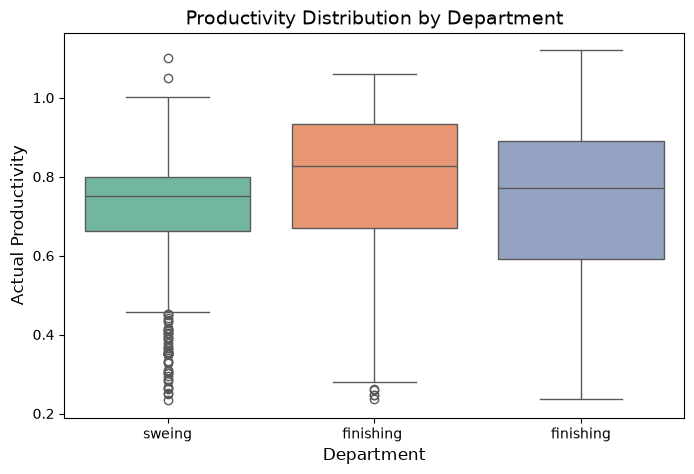

In [11]:
# Plot 3: Boxplot - Productivity by Department
plt.figure(figsize=(8, 5))
sns.boxplot(x='department', y='actual_productivity', data=df, palette='Set2')
plt.title('Productivity Distribution by Department', fontsize=14)
plt.xlabel('Department', fontsize=12)
plt.ylabel('Actual Productivity', fontsize=12)
plt.show()

In [ ]:
00000

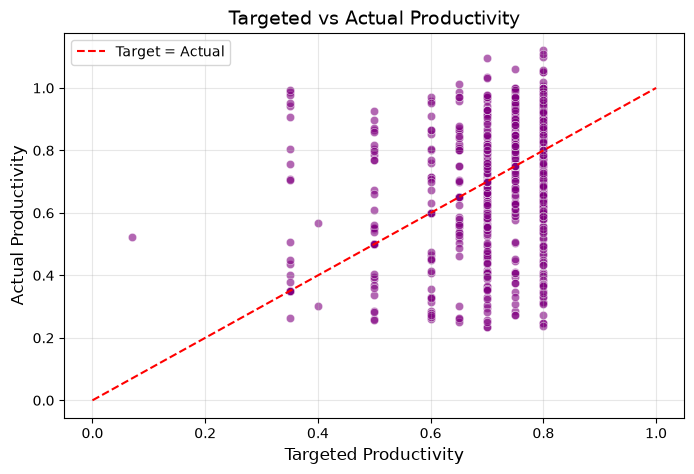

In [12]:
# Plot 4: Scatter Plot - Targeted vs Actual Productivity
plt.figure(figsize=(8, 5))
sns.scatterplot(x='targeted_productivity', y='actual_productivity',
                data=df, alpha=0.6, color='purple')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Target = Actual')

plt.title('Targeted vs Actual Productivity', fontsize=14)
plt.xlabel('Targeted Productivity', fontsize=12)
plt.ylabel('Actual Productivity', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()